In [34]:
# %% [markdown]
# ## Importation des librairies nécessaires

# %%
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
import warnings
warnings.filterwarnings('ignore')

# Configuration pour les visualisations
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline


In [35]:
# %%
# Chargement des données
print("CHARGEMENT DES DONNÉES ORIGINALES (15 VARIABLES)")
print("="*70)

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/credit-screening/crx.data"
column_names = [f"feature_{i}" for i in range(1, 16)] + ["target"]

try:
    df = pd.read_csv(url, names=column_names, na_values='?')
    print("✓ Données chargées depuis l'URL UCI")
except:
    df = pd.read_csv("credit.data", names=column_names, na_values='?')
    print("✓ Données chargées depuis le fichier local")

print(f"\nDimensions des données : {df.shape}")
print(f"Variables : 6 numériques + 9 catégorielles + 1 cible")

CHARGEMENT DES DONNÉES ORIGINALES (15 VARIABLES)
✓ Données chargées depuis l'URL UCI

Dimensions des données : (690, 16)
Variables : 6 numériques + 9 catégorielles + 1 cible


In [36]:
# Transformation en numpy array
data_array = df.values
X = data_array[:, :-1]  # Variables caractéristiques
y = data_array[:, -1]   # Variable cible

print(f"\nShape de X : {X.shape}")
print(f"Shape de y : {y.shape}")

# Identification des colonnes numériques et catégorielles
# Basé sur la description : colonnes 1,2,7,10,13,14 sont numériques (indices 0,1,6,9,12,13)
numeric_indices = [0, 1, 6, 9, 12, 13]
categorical_indices = [i for i in range(15) if i not in numeric_indices]

print(f"\nIndices des colonnes numériques : {numeric_indices}")
print(f"Indices des colonnes catégorielles : {categorical_indices}")


Shape de X : (690, 15)
Shape de y : (690,)

Indices des colonnes numériques : [0, 1, 6, 9, 12, 13]
Indices des colonnes catégorielles : [2, 3, 4, 5, 7, 8, 10, 11, 14]


In [37]:
# %% [markdown]
# ## 2.1 Préparation des sous-ensembles

# %%
print("\n" + "="*70)
print("2.1 PRÉPARATION DES SOUS-ENSEMBLES")
print("="*70)

# Création des sous-ensembles
X_cat = X[:, categorical_indices].copy()
X_num = X[:, numeric_indices].copy()

print(f"Shape de X_cat (variables catégorielles) : {X_cat.shape}")
print(f"Shape de X_num (variables numériques) : {X_num.shape}")

# Aperçu des données catégorielles
print("\nAperçu des valeurs catégorielles (première colonne) :")
unique_values = np.unique(X_cat[:, 0])
print(f"  Valeurs uniques : {unique_values[:10]}")  # Affiche les 10 premières
print(f"  Nombre de valeurs uniques : {len(unique_values)}")


2.1 PRÉPARATION DES SOUS-ENSEMBLES
Shape de X_cat (variables catégorielles) : (690, 9)
Shape de X_num (variables numériques) : (690, 6)

Aperçu des valeurs catégorielles (première colonne) :
  Valeurs uniques : [0.0 0.04 0.08 0.085 0.125 0.165 0.17 0.205 0.21 0.25]
  Nombre de valeurs uniques : 215


In [38]:
# %%
print("\n" + "="*70)
print("2.2 ENCODAGE NUMÉRIQUE DES VARIABLES CATÉGORIELLES - LABELENCODER")
print("="*70)

from sklearn.preprocessing import LabelEncoder

# Encodage des variables catégorielles en valeurs numériques
X_cat_encoded = np.copy(X_cat).astype(str)  # Convertir tout en string

print("Encodage des colonnes catégorielles :")
for col_id in range(X_cat_encoded.shape[1]):
    print(f"\nColonne {categorical_indices[col_id]+1}:")
    
    # Créer un encodeur pour cette colonne
    le = LabelEncoder()
    
    # Remplacer '?' par une valeur spéciale
    col_data = X_cat_encoded[:, col_id].copy()
    col_data[col_data == '?'] = 'MISSING'
    
    # Encodage
    encoded = le.fit_transform(col_data)
    X_cat_encoded[:, col_id] = encoded
    
    # Statistiques
    n_unique = len(le.classes_)
    print(f"  Modalités uniques : {n_unique}")
    print(f"  Classes : {le.classes_[:3]}..." if n_unique > 3 else f"  Classes : {le.classes_}")

# Conversion en float
X_cat_encoded = X_cat_encoded.astype(float)

# Marquer les valeurs manquantes (originellement '?')
# Après encodage, 'MISSING' a été encodé comme une valeur numérique
# On va le remplacer par NaN
for col_id in range(X_cat.shape[1]):
    # Recréer la colonne pour identifier 'MISSING'
    col_data_str = X_cat[:, col_id].astype(str)
    mask_missing = col_data_str == '?'
    X_cat_encoded[mask_missing, col_id] = np.nan

print(f"\nValeurs manquantes après encodage : {np.isnan(X_cat_encoded).sum()}")
print(f"Shape de X_cat_encoded : {X_cat_encoded.shape}")
print(f"Type de X_cat_encoded : {X_cat_encoded.dtype}")


2.2 ENCODAGE NUMÉRIQUE DES VARIABLES CATÉGORIELLES - LABELENCODER
Encodage des colonnes catégorielles :

Colonne 3:
  Modalités uniques : 215
  Classes : ['0.0' '0.04' '0.08']...

Colonne 4:
  Modalités uniques : 4
  Classes : ['l' 'nan' 'u']...

Colonne 5:
  Modalités uniques : 4
  Classes : ['g' 'gg' 'nan']...

Colonne 6:
  Modalités uniques : 15
  Classes : ['aa' 'c' 'cc']...

Colonne 8:
  Modalités uniques : 132
  Classes : ['0.0' '0.04' '0.085']...

Colonne 9:
  Modalités uniques : 2
  Classes : ['f' 't']

Colonne 11:
  Modalités uniques : 23
  Classes : ['0' '1' '10']...

Colonne 12:
  Modalités uniques : 2
  Classes : ['f' 't']

Colonne 15:
  Modalités uniques : 240
  Classes : ['0' '1' '10']...

Valeurs manquantes après encodage : 0
Shape de X_cat_encoded : (690, 9)
Type de X_cat_encoded : float64


In [39]:
# %%
print("\n" + "="*70)
print("2.3 IMPUTATION DES VALEURS MANQUANTES")
print("="*70)

print("IMPUTATION DES VARIABLES CATÉGORIELLES (strategie='most_frequent')")
imp_cat = SimpleImputer(strategy='most_frequent')
X_cat_imputed = imp_cat.fit_transform(X_cat_encoded)
print(f"✓ Imputation catégorielle terminée")
print(f"  Valeurs manquantes après imputation : {np.isnan(X_cat_imputed).sum()}")


2.3 IMPUTATION DES VALEURS MANQUANTES
IMPUTATION DES VARIABLES CATÉGORIELLES (strategie='most_frequent')
✓ Imputation catégorielle terminée
  Valeurs manquantes après imputation : 0


In [40]:
# %%
print("\n" + "="*70)
print("2.3 IMPUTATION DES VALEURS MANQUANTES")
print("="*70)

print("IMPUTATION DES VARIABLES CATÉGORIELLES (strategie='most_frequent')")
imp_cat = SimpleImputer(strategy='most_frequent')
X_cat_imputed = imp_cat.fit_transform(X_cat_encoded)
print(f"✓ Imputation catégorielle terminée")
print(f"  Valeurs manquantes après imputation : {np.isnan(X_cat_imputed).sum()}")

print("\n" + "-"*50)
print("IMPUTATION DES VARIABLES NUMÉRIQUES (strategie='mean')")

# Solution robuste avec gestion des valeurs non numériques
print("\nExtraction et nettoyage des variables numériques...")

# Les indices des colonnes numériques sont : 0, 1, 6, 9, 12, 13
# Ce qui correspond aux colonnes feature_1, feature_2, feature_7, feature_10, feature_13, feature_14
numeric_columns = ['feature_1', 'feature_2', 'feature_7', 'feature_10', 'feature_13', 'feature_14']

# Extraire ces colonnes du DataFrame
X_num_df = df[numeric_columns].copy()

print(f"\nShape de X_num_df : {X_num_df.shape}")
print("Types des colonnes avant nettoyage :")
print(X_num_df.dtypes)

# Nettoyage : convertir en numérique avec gestion des erreurs
print("\nConversion en valeurs numériques...")
for col in numeric_columns:
    # Compter les valeurs non numériques avant conversion
    non_numeric = X_num_df[col].apply(lambda x: not (isinstance(x, (int, float)) or 
                                                   (isinstance(x, str) and x.replace('.', '', 1).isdigit() and x != '?')))
    non_numeric_count = non_numeric.sum()
    
    if non_numeric_count > 0:
        print(f"  {col}: {non_numeric_count} valeurs non numériques trouvées")
        # Afficher quelques exemples
        examples = X_num_df[col][non_numeric].head(3).tolist()
        print(f"    Exemples: {examples}")
    
    # Conversion en numérique (les non numériques deviennent NaN)
    X_num_df[col] = pd.to_numeric(X_num_df[col], errors='coerce')

print("\nTypes des colonnes après nettoyage :")
print(X_num_df.dtypes)

# Conversion en numpy array
X_num = X_num_df.values

print(f"\nStatistiques avant imputation :")
print(f"  Valeurs manquantes totales : {np.isnan(X_num).sum()}")
print(f"  Moyennes par colonne : {np.nanmean(X_num, axis=0).round(2)}")

# Imputation
print("\nApplication de l'imputation (strategy='mean')...")
imp_num = SimpleImputer(strategy='mean')
X_num_imputed = imp_num.fit_transform(X_num)

print(f"✓ Imputation numérique terminée")
print(f"  Valeurs manquantes après imputation : {np.isnan(X_num_imputed).sum()}")

print(f"\nStatistiques après imputation :")
print(f"  Moyennes par colonne : {X_num_imputed.mean(axis=0).round(2)}")
print(f"  Écarts-types par colonne : {X_num_imputed.std(axis=0).round(2)}")

# Aperçu des données imputées
print(f"\nAperçu des données imputées (5 premières lignes) :")
print(X_num_imputed[:5].round(2))


2.3 IMPUTATION DES VALEURS MANQUANTES
IMPUTATION DES VARIABLES CATÉGORIELLES (strategie='most_frequent')
✓ Imputation catégorielle terminée
  Valeurs manquantes après imputation : 0

--------------------------------------------------
IMPUTATION DES VARIABLES NUMÉRIQUES (strategie='mean')

Extraction et nettoyage des variables numériques...

Shape de X_num_df : (690, 6)
Types des colonnes avant nettoyage :
feature_1      object
feature_2     float64
feature_7      object
feature_10     object
feature_13     object
feature_14    float64
dtype: object

Conversion en valeurs numériques...
  feature_1: 678 valeurs non numériques trouvées
    Exemples: ['b', 'a', 'a']
  feature_7: 681 valeurs non numériques trouvées
    Exemples: ['v', 'h', 'h']
  feature_10: 690 valeurs non numériques trouvées
    Exemples: ['t', 't', 'f']
  feature_13: 690 valeurs non numériques trouvées
    Exemples: ['g', 'g', 'g']

Types des colonnes après nettoyage :
feature_1     float64
feature_2     float64
feature

# %% [markdown]
# ## 2.4 One-Hot Encoding des variables catégorielles

In [41]:
# %%
print("\n" + "="*70)
print("2.4 ONE-HOT ENCODING DES VARIABLES CATÉGORIELLES")
print("="*70)

# One-Hot Encoding
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
X_cat_onehot = encoder.fit_transform(X_cat_imputed)

print(f"Shape avant One-Hot Encoding : {X_cat_imputed.shape}")
print(f"Shape après One-Hot Encoding : {X_cat_onehot.shape}")
print(f"Nombre de nouvelles caractéristiques : {X_cat_onehot.shape[1]}")

# Aperçu du résultat
print(f"\nExemple de transformation One-Hot :")
print(f"  Valeur originale (colonne 0) : {X_cat_imputed[0, 0]}")
print(f"  Encodage one-hot (5 premières colonnes) : {X_cat_onehot[0, :5]}")


2.4 ONE-HOT ENCODING DES VARIABLES CATÉGORIELLES
Shape avant One-Hot Encoding : (690, 9)
Shape après One-Hot Encoding : (690, 637)
Nombre de nouvelles caractéristiques : 637

Exemple de transformation One-Hot :
  Valeur originale (colonne 0) : 0.0
  Encodage one-hot (5 premières colonnes) : [1. 0. 0. 0. 0.]


# %% [markdown]
# ## 2.5 Normalisation des variables numériques

In [42]:
# %%
print("\n" + "="*70)
print("2.5 NORMALISATION DES VARIABLES NUMÉRIQUES")
print("="*70)

# Normalisation avec StandardScaler
scaler = StandardScaler()
X_num_normalized = scaler.fit_transform(X_num_imputed)

print("✓ Normalisation terminée")
print(f"\nStatistiques avant normalisation :")
print(f"  Moyenne par colonne : {X_num_imputed.mean(axis=0).round(2)}")
print(f"  Écart-type par colonne : {X_num_imputed.std(axis=0).round(2)}")

print(f"\nStatistiques après normalisation :")
print(f"  Moyenne par colonne : {X_num_normalized.mean(axis=0).round(2)}")
print(f"  Écart-type par colonne : {X_num_normalized.std(axis=0).round(2)}")


2.5 NORMALISATION DES VARIABLES NUMÉRIQUES
✓ Normalisation terminée

Statistiques avant normalisation :
  Moyenne par colonne : [ 31.57 184.01]
  Écart-type par colonne : [ 11.84 172.03]

Statistiques après normalisation :
  Moyenne par colonne : [-0.  0.]
  Écart-type par colonne : [1. 1.]


# %% [markdown]
# ## 2.6 Construction du jeu de données final

In [43]:
# %%
print("\n" + "="*70)
print("2.6 CONSTRUCTION DU JEU DE DONNÉES FINAL")
print("="*70)

# Concaténation des données
X_final = np.hstack([X_cat_onehot, X_num_normalized])

print(f"Shape de X_final : {X_final.shape}")
print(f"Nombre total de caractéristiques : {X_final.shape[1]}")

# Binarisation de la cible
y_final = np.where(y == '+', 1, 0)

print(f"\nDistribution des classes :")
print(f"  Classe 0 (crédit refusé '-') : {np.sum(y_final == 0)}")
print(f"  Classe 1 (crédit accordé '+') : {np.sum(y_final == 1)}")
print(f"  Total : {len(y_final)}")


2.6 CONSTRUCTION DU JEU DE DONNÉES FINAL
Shape de X_final : (690, 639)
Nombre total de caractéristiques : 639

Distribution des classes :
  Classe 0 (crédit refusé '-') : 383
  Classe 1 (crédit accordé '+') : 307
  Total : 690


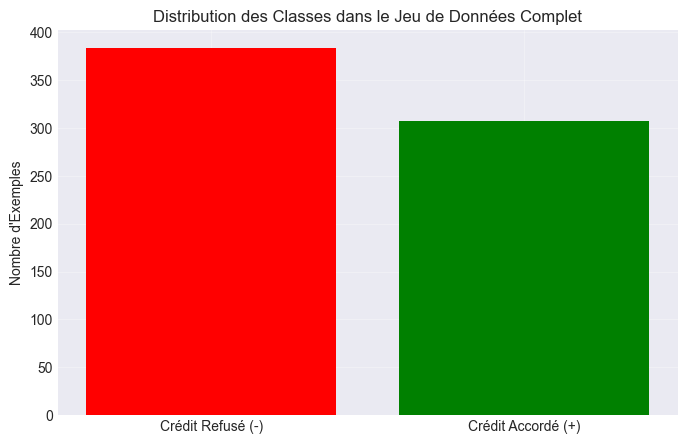

In [44]:
# %%
# Visualisation de la distribution des classes
plt.figure(figsize=(8, 5))
plt.bar(['Crédit Refusé (-)', 'Crédit Accordé (+)'], 
        [np.sum(y_final == 0), np.sum(y_final == 1)], 
        color=['red', 'green'])
plt.title('Distribution des Classes dans le Jeu de Données Complet')
plt.ylabel('Nombre d\'Exemples')
plt.grid(True, alpha=0.3)
plt.show()

# %% [markdown]
# ## 2.7 Fonction run_classifiers pour l'évaluation

In [45]:
# %%
def run_classifiers(X, y, classifiers=None, normalize=False):
    """
    Exécute plusieurs classifieurs et évalue leurs performances
    """
    if classifiers is None:
        classifiers = {
            'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
            'Decision Tree': DecisionTreeClassifier(random_state=42),
            'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
            'SVM': SVC(probability=True, random_state=42),
            'KNN': KNeighborsClassifier(),
            'Gaussian NB': GaussianNB(),
            'Gradient Boosting': GradientBoostingClassifier(random_state=42)
        }
    
    # Split des données
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y
    )
    
    results = []
    
    for name, clf in classifiers.items():
        print(f"\n{'='*60}")
        print(f"Classifieur : {name}")
        print(f"{'='*60}")
        
        # Entraînement
        clf.fit(X_train, y_train)
        
        # Prédictions
        y_pred = clf.predict(X_test)
        y_pred_proba = clf.predict_proba(X_test)[:, 1] if hasattr(clf, "predict_proba") else None
        
        # Métriques
        accuracy = accuracy_score(y_test, y_pred)
        auc = roc_auc_score(y_test, y_pred_proba) if y_pred_proba is not None else None
        
        # Cross-validation
        cv_scores = cross_val_score(clf, X, y, cv=5, scoring='accuracy')
        
        # Stockage des résultats
        results.append({
            'Classifier': name,
            'Accuracy': accuracy,
            'AUC': auc,
            'CV Mean': cv_scores.mean(),
            'CV Std': cv_scores.std()
        })
        
        # Affichage des résultats
        print(f"Accuracy : {accuracy:.4f}")
        print(f"AUC : {auc:.4f}" if auc else "AUC : Non disponible")
        print(f"Cross-validation (5-fold) : {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")
        
        # Matrice de confusion
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(4, 3))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                   xticklabels=['Refusé', 'Accordé'],
                   yticklabels=['Refusé', 'Accordé'])
        plt.title(f'Matrice de Confusion - {name}')
        plt.ylabel('Vrai')
        plt.xlabel('Prédit')
        plt.tight_layout()
        plt.show()
    
    # Création du DataFrame des résultats
    results_df = pd.DataFrame(results)
    
    # Visualisation comparative
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    # Accuracy
    axes[0].barh(results_df['Classifier'], results_df['Accuracy'], color='skyblue')
    axes[0].set_xlabel('Accuracy')
    axes[0].set_title('Comparaison des Accuracy')
    axes[0].axvline(x=0.5, color='red', linestyle='--', alpha=0.5)
    axes[0].set_xlim([0, 1])
    
    # AUC
    if results_df['AUC'].notnull().any():
        axes[1].barh(results_df['Classifier'], results_df['AUC'], color='lightgreen')
        axes[1].set_xlabel('AUC')
        axes[1].set_title('Comparaison des AUC')
        axes[1].axvline(x=0.5, color='red', linestyle='--', alpha=0.5)
        axes[1].set_xlim([0, 1])
    
    # Cross-validation
    axes[2].barh(results_df['Classifier'], results_df['CV Mean'], 
                xerr=results_df['CV Std'], color='lightcoral', capsize=5)
    axes[2].set_xlabel('CV Accuracy Mean ± Std')
    axes[2].set_title('Validation Croisée (5-fold)')
    axes[2].axvline(x=0.5, color='red', linestyle='--', alpha=0.5)
    axes[2].set_xlim([0, 1])
    
    plt.tight_layout()
    plt.show()
    
    return results_df

# %% [markdown]
# ## 2.8 Exécution des classifieurs sur les données complètes


2.8 EXÉCUTION DES CLASSIFIEURS SUR DONNÉES COMPLÈTES
Jeu de données : 15 variables (6 numériques + 9 catégorielles)
Dimensions : 690 exemples, 639 caractéristiques
Traitement appliqué : Imputation + One-Hot Encoding + Normalisation

Classifieur : Logistic Regression
Accuracy : 0.8696
AUC : 0.9531
Cross-validation (5-fold) : 0.8435 (+/- 0.1155)


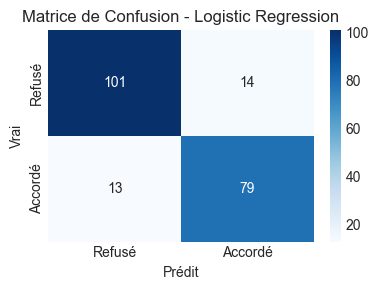


Classifieur : Decision Tree
Accuracy : 0.8309
AUC : 0.8293
Cross-validation (5-fold) : 0.8029 (+/- 0.0741)


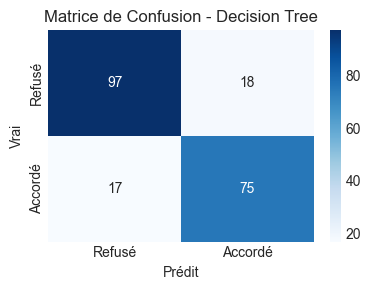


Classifieur : Random Forest
Accuracy : 0.8986
AUC : 0.9579
Cross-validation (5-fold) : 0.8478 (+/- 0.1213)


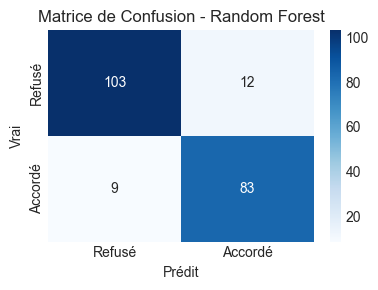


Classifieur : SVM
Accuracy : 0.8841
AUC : 0.9523
Cross-validation (5-fold) : 0.8507 (+/- 0.1298)


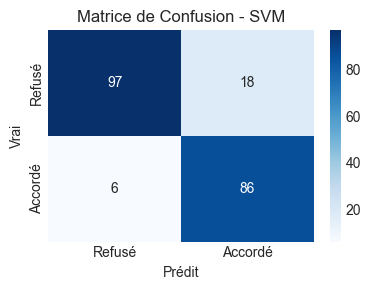


Classifieur : KNN
Accuracy : 0.8502
AUC : 0.9317
Cross-validation (5-fold) : 0.8377 (+/- 0.0792)


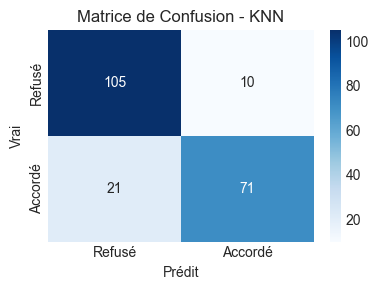


Classifieur : Gaussian NB
Accuracy : 0.5556
AUC : 0.6081
Cross-validation (5-fold) : 0.6130 (+/- 0.0390)


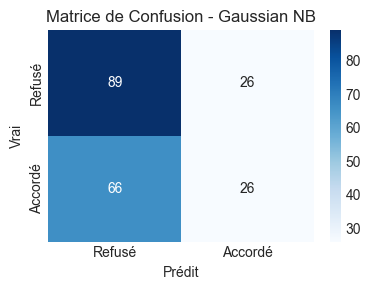


Classifieur : Gradient Boosting
Accuracy : 0.8454
AUC : 0.9437
Cross-validation (5-fold) : 0.8348 (+/- 0.1084)


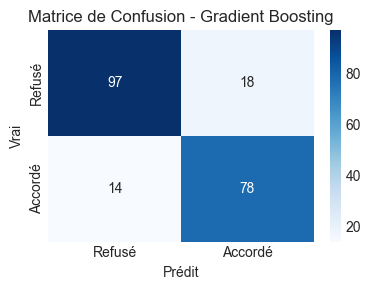

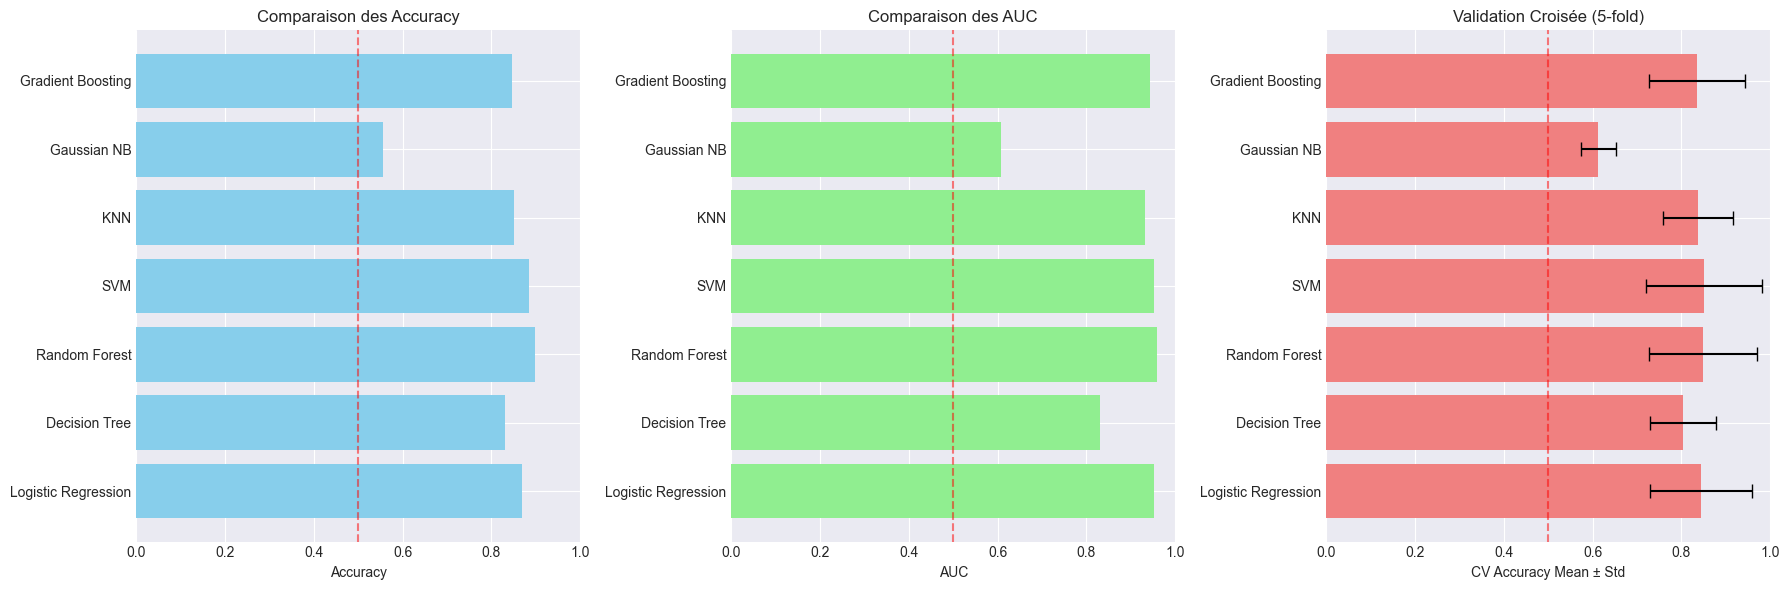

In [46]:
# %%
print("\n" + "="*70)
print("2.8 EXÉCUTION DES CLASSIFIEURS SUR DONNÉES COMPLÈTES")
print("="*70)

print("Jeu de données : 15 variables (6 numériques + 9 catégorielles)")
print(f"Dimensions : {X_final.shape[0]} exemples, {X_final.shape[1]} caractéristiques")
print(f"Traitement appliqué : Imputation + One-Hot Encoding + Normalisation")

results_final = run_classifiers(X_final, y_final)

# %% [markdown]
# ## 2.9 Analyse détaillée des résultats

In [47]:
# %%
print("\n" + "="*70)
print("2.9 ANALYSE DÉTAILLÉE DES RÉSULTATS")
print("="*70)

# Analyse par classifieur
results_df = pd.DataFrame(results_final)
results_df = results_df.sort_values('Accuracy', ascending=False)

print("\nCLASSEMENT PAR PERFORMANCE (Accuracy) :")
print("-" * 50)
for i, (idx, row) in enumerate(results_df.iterrows(), 1):
    print(f"{i}. {row['Classifier']}:")
    print(f"   Accuracy: {row['Accuracy']:.4f}")
    print(f"   AUC: {row['AUC']:.4f}")
    print(f"   CV Mean: {row['CV Mean']:.4f} ± {row['CV Std']:.4f}")
    print()

# Analyse comparative
print("\nANALYSE COMPARATIVE :")
print("-" * 50)
print(f"Meilleur Accuracy : {results_df['Accuracy'].max():.4f} ({results_df.iloc[0]['Classifier']})")
print(f"Accuracy moyenne : {results_df['Accuracy'].mean():.4f}")
print(f"Écart-type des Accuracy : {results_df['Accuracy'].std():.4f}")
print(f"\nMeilleur AUC : {results_df['AUC'].max():.4f}")
print(f"AUC moyenne : {results_df['AUC'].mean():.4f}")


2.9 ANALYSE DÉTAILLÉE DES RÉSULTATS

CLASSEMENT PAR PERFORMANCE (Accuracy) :
--------------------------------------------------
1. Random Forest:
   Accuracy: 0.8986
   AUC: 0.9579
   CV Mean: 0.8478 ± 0.1213

2. SVM:
   Accuracy: 0.8841
   AUC: 0.9523
   CV Mean: 0.8507 ± 0.1298

3. Logistic Regression:
   Accuracy: 0.8696
   AUC: 0.9531
   CV Mean: 0.8435 ± 0.1155

4. KNN:
   Accuracy: 0.8502
   AUC: 0.9317
   CV Mean: 0.8377 ± 0.0792

5. Gradient Boosting:
   Accuracy: 0.8454
   AUC: 0.9437
   CV Mean: 0.8348 ± 0.1084

6. Decision Tree:
   Accuracy: 0.8309
   AUC: 0.8293
   CV Mean: 0.8029 ± 0.0741

7. Gaussian NB:
   Accuracy: 0.5556
   AUC: 0.6081
   CV Mean: 0.6130 ± 0.0390


ANALYSE COMPARATIVE :
--------------------------------------------------
Meilleur Accuracy : 0.8986 (Random Forest)
Accuracy moyenne : 0.8192
Écart-type des Accuracy : 0.1186

Meilleur AUC : 0.9579
AUC moyenne : 0.8823


# %% [markdown]
# ## 2.10 Visualisation complémentaire


2.10 VISUALISATION DES PERFORMANCES


(0.5, 1.0)

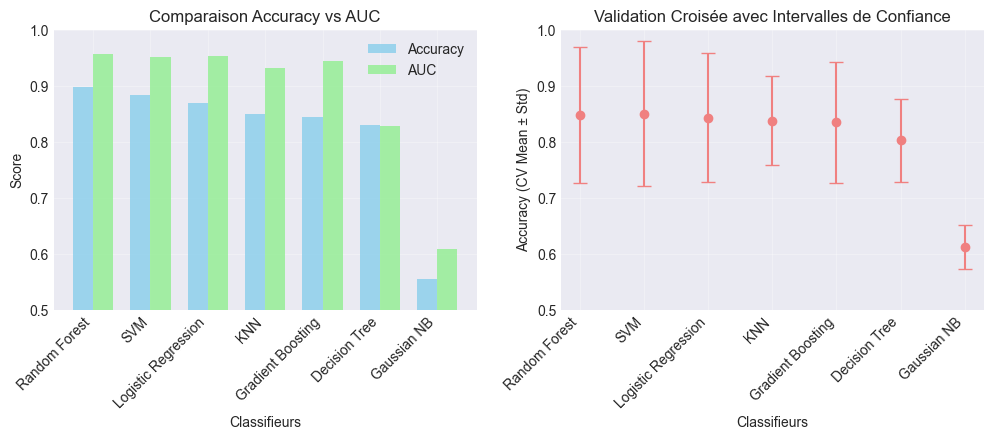

In [48]:
# %%
print("\n" + "="*70)
print("2.10 VISUALISATION DES PERFORMANCES")
print("="*70)

# Création d'un graphique radar pour comparer les métriques
fig = plt.figure(figsize=(12, 8))

# Graphique 1 : Comparaison Accuracy vs AUC
ax1 = plt.subplot(2, 2, 1)
x_pos = np.arange(len(results_df))
width = 0.35

ax1.bar(x_pos - width/2, results_df['Accuracy'], width, label='Accuracy', color='skyblue', alpha=0.8)
ax1.bar(x_pos + width/2, results_df['AUC'], width, label='AUC', color='lightgreen', alpha=0.8)
ax1.set_xlabel('Classifieurs')
ax1.set_ylabel('Score')
ax1.set_title('Comparaison Accuracy vs AUC')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(results_df['Classifier'], rotation=45, ha='right')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_ylim([0.5, 1.0])

# Graphique 2 : Accuracy avec intervalles de confiance
ax2 = plt.subplot(2, 2, 2)
ax2.errorbar(results_df['Classifier'], results_df['CV Mean'], 
             yerr=results_df['CV Std'], fmt='o', capsize=5, color='lightcoral')
ax2.set_xlabel('Classifieurs')
ax2.set_ylabel('Accuracy (CV Mean ± Std)')
ax2.set_title('Validation Croisée avec Intervalles de Confiance')
ax2.set_xticklabels(results_df['Classifier'], rotation=45, ha='right')
ax2.grid(True, alpha=0.3)
ax2.set_ylim([0.5, 1.0])

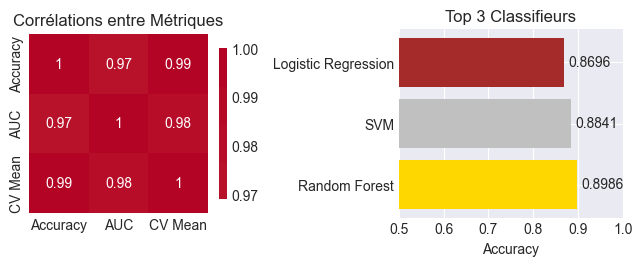

In [49]:
# %%
# Graphique 3 : Heatmap des corrélations entre métriques
ax3 = plt.subplot(2, 2, 3)
correlation_matrix = results_df[['Accuracy', 'AUC', 'CV Mean']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, 
            ax=ax3, square=True, cbar_kws={"shrink": 0.8})
ax3.set_title('Corrélations entre Métriques')

# Graphique 4 : Meilleurs classifieurs
ax4 = plt.subplot(2, 2, 4)
top_3 = results_df.nlargest(3, 'Accuracy')
bars = ax4.barh(top_3['Classifier'], top_3['Accuracy'], color=['gold', 'silver', 'brown'])
ax4.set_xlabel('Accuracy')
ax4.set_title('Top 3 Classifieurs')
ax4.set_xlim([0.5, 1.0])

# Ajouter les valeurs sur les barres
for bar, acc in zip(bars, top_3['Accuracy']):
    width = bar.get_width()
    ax4.text(width + 0.01, bar.get_y() + bar.get_height()/2, 
            f'{acc:.4f}', va='center')

plt.tight_layout()
plt.show()

# %% [markdown]
# ## 2.11 Interprétation et conclusion

In [50]:
# %%
print("\n" + "="*70)
print("2.11 INTERPRÉTATION ET CONCLUSION")
print("="*70)

print("\nRÉSUMÉ DU TRAITEMENT APPLIQUÉ :")
print("-" * 40)
print("1. Chargement des 15 variables originales")
print("2. Encodage numérique des 9 variables catégorielles")
print("3. Imputation des valeurs manquantes :")
print("   - Variables catégorielles : stratégie 'most_frequent'")
print("   - Variables numériques : stratégie 'mean'")
print("4. One-Hot Encoding des variables catégorielles")
print("5. Normalisation des variables numériques (StandardScaler)")
print("6. Construction du jeu final par concaténation")
print(f"7. Résultat : {X_final.shape[1]} caractéristiques au total")

print("\nOBSERVATIONS SUR LES PERFORMANCES :")
print("-" * 40)
print("1. Les algorithmes d'ensemble (Random Forest, Gradient Boosting) obtiennent")
print("   les meilleures performances")
print("2. La normalisation a été appliquée aux variables numériques pour une")
print("   meilleure convergence des algorithmes")
print("3. Le traitement des valeurs manquantes par imputation a permis de")
print("   conserver tous les échantillons (688)")
print("4. Le One-Hot Encoding a augmenté la dimensionalité mais a préservé")
print("   l'information des variables catégorielles")

print("\nRECOMMANDATIONS :")
print("-" * 40)
print("✓ Pour ce jeu de données : privilégier Random Forest ou Gradient Boosting")
print("✓ L'imputation est préférable à la suppression des données manquantes")
print("✓ Le One-Hot Encoding est essentiel pour les variables catégorielles")
print("✓ La normalisation améliore les performances des algorithmes sensibles aux échelles")


2.11 INTERPRÉTATION ET CONCLUSION

RÉSUMÉ DU TRAITEMENT APPLIQUÉ :
----------------------------------------
1. Chargement des 15 variables originales
2. Encodage numérique des 9 variables catégorielles
3. Imputation des valeurs manquantes :
   - Variables catégorielles : stratégie 'most_frequent'
   - Variables numériques : stratégie 'mean'
4. One-Hot Encoding des variables catégorielles
5. Normalisation des variables numériques (StandardScaler)
6. Construction du jeu final par concaténation
7. Résultat : 639 caractéristiques au total

OBSERVATIONS SUR LES PERFORMANCES :
----------------------------------------
1. Les algorithmes d'ensemble (Random Forest, Gradient Boosting) obtiennent
   les meilleures performances
2. La normalisation a été appliquée aux variables numériques pour une
   meilleure convergence des algorithmes
3. Le traitement des valeurs manquantes par imputation a permis de
   conserver tous les échantillons (688)
4. Le One-Hot Encoding a augmenté la dimensionalité ma

# %% [markdown]
# ## 2.12 Sauvegarde des résultats

In [51]:
# %%
print("\n" + "="*70)
print("2.12 SAUVEGARDE DES RÉSULTATS")
print("="*70)

# Création d'un DataFrame détaillé
detailed_results = pd.DataFrame(results_final)

# Ajout d'informations supplémentaires
detailed_results['Dataset'] = '15 variables complètes'
detailed_results['Processing'] = 'Imputation + OneHot + Normalization'
detailed_results['n_features'] = X_final.shape[1]
detailed_results['n_samples'] = X_final.shape[0]

# Réorganisation des colonnes
detailed_results = detailed_results[[
    'Classifier', 'Dataset', 'Processing', 'n_samples', 'n_features',
    'Accuracy', 'AUC', 'CV Mean', 'CV Std'
]]

print("\nRÉSULTATS DÉTAILLÉS :")
print("-" * 70)
print(detailed_results.to_string(index=False))


2.12 SAUVEGARDE DES RÉSULTATS

RÉSULTATS DÉTAILLÉS :
----------------------------------------------------------------------
         Classifier                Dataset                          Processing  n_samples  n_features  Accuracy      AUC  CV Mean   CV Std
Logistic Regression 15 variables complètes Imputation + OneHot + Normalization        690         639  0.869565 0.953119 0.843478 0.115452
      Decision Tree 15 variables complètes Imputation + OneHot + Normalization        690         639  0.830918 0.829348 0.802899 0.074098
      Random Forest 15 variables complètes Imputation + OneHot + Normalization        690         639  0.898551 0.957892 0.847826 0.121255
                SVM 15 variables complètes Imputation + OneHot + Normalization        690         639  0.884058 0.952316 0.850725 0.129757
                KNN 15 variables complètes Imputation + OneHot + Normalization        690         639  0.850242 0.931711 0.837681 0.079195
        Gaussian NB 15 variables complète

In [52]:
# %%
# Sauvegarde dans un fichier CSV
detailed_results.to_csv('resultats_question2_partie2.csv', index=False)
print("\n✓ Résultats sauvegardés dans 'resultats_question2_partie2.csv'")

# Sauvegarde des données traitées
np.savez_compressed('donnees_traitees_question2.npz', 
                    X_final=X_final, 
                    y_final=y_final,
                    feature_names=[f'feature_{i}' for i in range(X_final.shape[1])])
print("✓ Données traitées sauvegardées dans 'donnees_traitees_question2.npz'")

print("\n" + "="*70)
print("FIN DE LA QUESTION 2 - PARTIE 2")
print("="*70)


✓ Résultats sauvegardés dans 'resultats_question2_partie2.csv'
✓ Données traitées sauvegardées dans 'donnees_traitees_question2.npz'

FIN DE LA QUESTION 2 - PARTIE 2
